In [9]:
import numpy as np
import pandas as pd
from riemann_ml.geometry import sample_branch_points, branch_gaps

import matplotlib.pyplot as plt
from riemann_ml.families import family_interior, family_nonseparating


In [2]:
def family_interior(n, seed, min_gap=0.08):
    rng =  np.random.default_rng(seed)
    filas = []
    for i in range(n):
        e = sample_branch_points(rng, min_gap)
        g = branch_gaps(e)

        fila = {
            "sample_id": f"INT{i+1:05d}",
            "family_id": "interior",
            "seed": seed,
        }
        for j, ej in enumerate(e, start=1):
            fila[f"e{j}"] = ej
        for j, gj in enumerate(g, start=1):
            fila[f"g{j}"] = gj
        fila["t1"] = np.nan
        fila["t2"] = np.nan
        fila["provisional_label"] = False

        filas.append(fila)
    return pd.DataFrame(filas)

In [3]:
df = family_interior(5, 20260905)
df

,sample_id,family_id,seed,e1,e2,e3,e4,e5,e6,g1,g2,g3,g4,g5,t1,t2,provisional_label
0,INT00001,interior,20260905,0.0,0.322806,0.478913,0.894029,1.0,2.0,0.322806,0.156107,0.415117,0.105971,1.0,NaN,NaN,False
1,INT00002,interior,20260905,0.0,0.162607,0.766989,0.906914,1.0,2.0,0.162607,0.604382,0.139925,0.093086,1.0,NaN,NaN,False
2,INT00003,interior,20260905,0.0,0.290548,0.601051,0.896980,1.0,2.0,0.290548,0.310503,0.295929,0.103020,1.0,NaN,NaN,False
3,INT00004,interior,20260905,0.0,0.094515,0.181444,0.571324,1.0,2.0,0.094515,0.086929,0.389881,0.428676,1.0,NaN,NaN,False
4,INT00005,interior,20260905,0.0,0.131272,0.360519,0.547349,1.0,2.0,0.131272,0.229247,0.186830,0.452651,1.0,NaN,NaN,False


In [5]:
def family_nonseparating(t_values, a=0.42, b=0.72):
    filas = []
    for i, t in enumerate(t_values):
        if not (0 < t < a < b < 1):
            raise ValueError(f"t={t} no cumple 0 < t < a < b < 1")

        e = np.array([0,t,a,b,1,2])
        g = branch_gaps(e)

        fila = {
            "sample_id": f"NSP{i+1:05d}",
            "family_id": "nonseparating",
            "seed": np.nan,
        }
        for j, ej in enumerate(e, start=1):
            fila[f"e{j}"] = ej
        for j, gj in enumerate(g, start=1):
            fila[f"g{j}"] = gj
        fila["t1"] = t
        fila["t2"] = np.nan
        fila["provisional_label"] = False

        filas.append(fila)
    return pd.DataFrame(filas)

In [6]:
df_nsp = family_nonseparating(np.geomspace(0.003, 0.22, 5))
df_nsp

,sample_id,family_id,seed,e1,e2,e3,e4,e5,e6,g1,g2,g3,g4,g5,t1,t2,provisional_label
0,NSP00001,nonseparating,NaN,0.0,0.003000,0.42,0.72,1.0,2.0,0.003000,0.417000,0.3,0.28,1.0,0.003000,NaN,False
1,NSP00002,nonseparating,NaN,0.0,0.008779,0.42,0.72,1.0,2.0,0.008779,0.411221,0.3,0.28,1.0,0.008779,NaN,False
2,NSP00003,nonseparating,NaN,0.0,0.025690,0.42,0.72,1.0,2.0,0.025690,0.394310,0.3,0.28,1.0,0.025690,NaN,False
3,NSP00004,nonseparating,NaN,0.0,0.075179,0.42,0.72,1.0,2.0,0.075179,0.344821,0.3,0.28,1.0,0.075179,NaN,False
4,NSP00005,nonseparating,NaN,0.0,0.220000,0.42,0.72,1.0,2.0,0.220000,0.200000,0.3,0.28,1.0,0.220000,NaN,False


In [7]:
family_nonseparating([0.1, 0.5])

ValueError: t=0.5 no cumple 0 < t < a < b < 1

In [8]:
def family_separating(eps_values, config):
    raise NotImplementedError(
        "Familia separante provisional: pendiente de validación matemática del generador."
    )

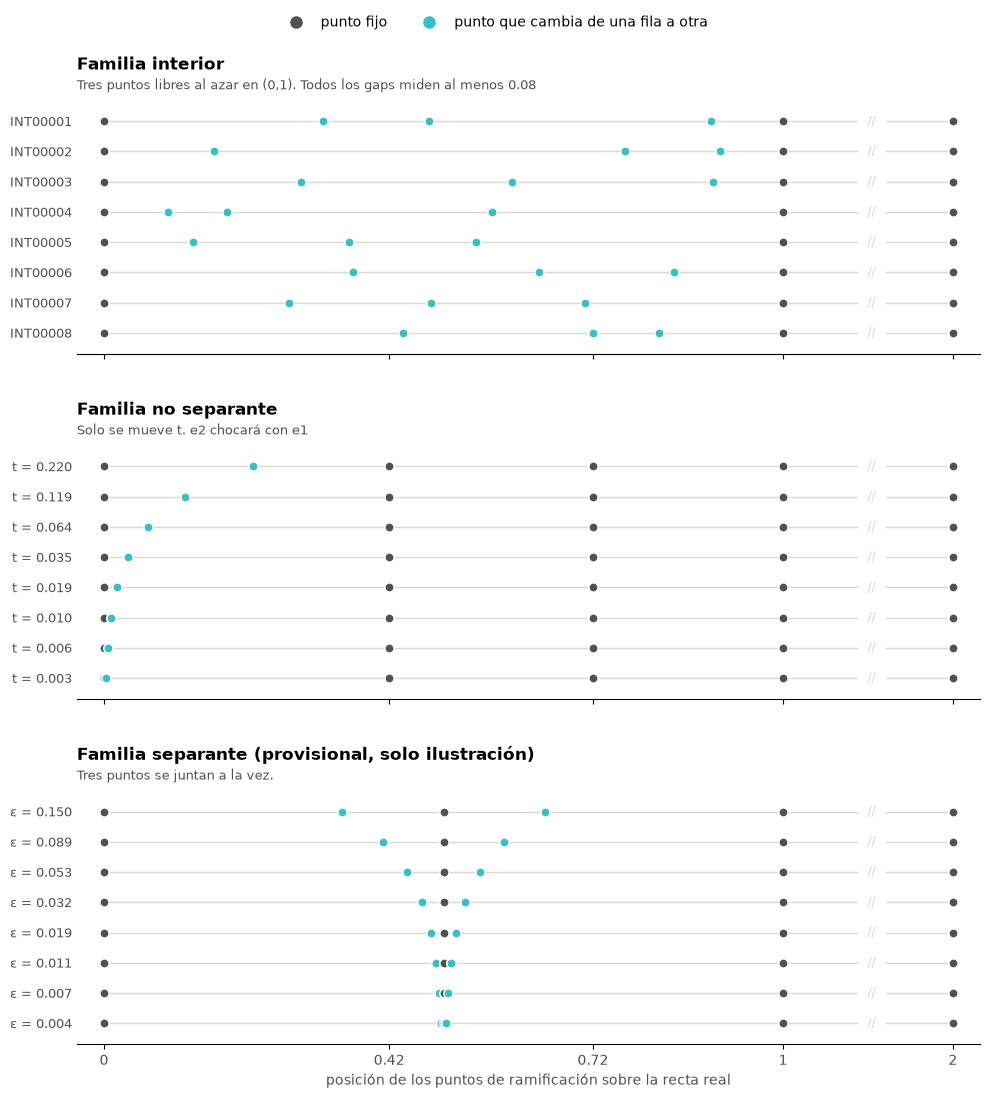

In [12]:
GRIS = "#52514e"
AZUL = "#33C1C4"
LINEA = "#d9d8d4"
COLS = [f"e{j}" for j in range(1, 7)]
X_DOS = 1.25


def posicion(x):
    return X_DOS if x == 2 else x

def dibujar_filas(ax, E, libres, etiquetas, titulo, nota):
    for fila, e in enumerate(E):
        y = len(E) - 1 - fila
        ax.hlines(y, 0, 1.11, color=LINEA, lw=1, zorder=1)
        ax.hlines(y, 1.15, X_DOS, color=LINEA, lw=1, zorder=1)
        ax.text(1.13, y, "//", color=LINEA, fontsize=9, ha="center", va="center")
        for j, x in enumerate(e):
            color = AZUL if j in libres else GRIS
            ax.scatter(posicion(x), y, s=46, color=color, edgecolor="white", linewidth=1.2, zorder=3)
    ax.set_yticks(range(len(E)))
    ax.set_yticklabels(etiquetas[::-1], fontsize=9, color=GRIS)
    ax.set_title(titulo, loc="left", fontsize=12, fontweight="bold", pad=22)
    ax.text(0, 1.03, nota, transform=ax.transAxes, fontsize=9.5, color=GRIS, va="bottom")
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(-0.04, X_DOS + 0.04)
    ax.set_ylim(-0.7, len(E) - 0.3)

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

df_int = family_interior(8, 20260905)
dibujar_filas(
    axes[0], df_int[COLS].to_numpy(), libres={1, 2, 3},
    etiquetas=list(df_int["sample_id"]),
    titulo="Familia interior",
    nota="Tres puntos libres al azar en (0,1). Todos los gaps miden al menos 0.08",
)

t_vals = np.geomspace(0.22, 0.003, 8)
df_nsp = family_nonseparating(t_vals)
dibujar_filas(
    axes[1], df_nsp[COLS].to_numpy(), libres={1},
    etiquetas=[f"t = {t:.3f}" for t in t_vals],
    titulo="Familia no separante",
    nota="Solo se mueve t. e2 chocará con e1",
)

eps_vals = np.geomspace(0.15, 0.004, 8)
E_sep = np.array([[0, 0.5 - eps, 0.5, 0.5 + eps, 1, 2] for eps in eps_vals])
dibujar_filas(
    axes[2], E_sep, libres={1, 3},
    etiquetas=[f"ε = {eps:.3f}" for eps in eps_vals],
    titulo="Familia separante (provisional, solo ilustración)",
    nota="Tres puntos se juntan a la vez. ",
)

axes[2].set_xticks([0, 0.42, 0.72, 1, X_DOS])
axes[2].set_xticklabels(["0", "0.42", "0.72", "1", "2"], color=GRIS)
axes[2].set_xlabel("posición de los puntos de ramificación sobre la recta real", color=GRIS)

fig.legend(
    handles=[
        plt.Line2D([], [], marker="o", ls="", color=GRIS, markersize=8, label="punto fijo"),
        plt.Line2D([], [], marker="o", ls="", color=AZUL, markersize=8, label="punto que cambia de una fila a otra"),
    ],
    loc="upper center", ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.0),
)
fig.tight_layout(rect=[0, 0, 1, 0.965], h_pad=3.0)
fig.savefig("familias.png", dpi=150, facecolor="white")
plt.show()